# Netflix Global Top 10 Viewership & Content Investment Strategy

## Introduction

The purpose of this project is to evaluate the performance of Netflix’s Top 10 content using the three datasets—All Weeks Countries Netflix, All Weeks Global Netflix, and Most Popular Netflix. By analyzing trends over time, regional performance, and overall popularity, this story identifies which types of content consistently perform well, which regions drive the most engagement, and where there are opportunities for improvement. 

The key message is to help stakeholders determine which content should continue to receive investment and which areas require strategic adjustments. The call to action is to prioritize funding and promotion for high-performing genres and globally consistent titles while improving or reevaluating underperforming categories and regions.

### 2.1 Data Preparation

Load the dataset as a Pandas data frame

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# Load the dataset file to Pandas DataFrame called 'popular'
popular = pd.read_excel('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/most-popular-netflix.xlsx')
nf_global = pd.read_excel('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/all-weeks-global-netflix.xlsx')
nf_countries = pd.read_excel('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/all-weeks-countries-netflix.xlsx')


C:\Users\MAYMA\Downloads\Bellevue_University\dsc530miniconda\envs\book_env\lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
C:\Users\MAYMA\Downloads\Bellevue_University\dsc530miniconda\envs\book_env\lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
C:\Users\MAYMA\Downloads\Bellevue_University\dsc530miniconda\envs\book_env\lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [3]:
# Preview the column names to verify structure
print(popular .columns)

Index(['category', 'rank', 'show_title', 'season_title',
       'hours_viewed_first_91_days', 'runtime', 'views_first_91_days'],
      dtype='object')


In [4]:
# Preview the column names to verify structure
print(nf_global .columns)

Index(['week', 'category', 'weekly_rank', 'show_title', 'season_title',
       'weekly_hours_viewed', 'runtime', 'weekly_views',
       'cumulative_weeks_in_top_10', 'is_staggered_launch',
       'episode_launch_details'],
      dtype='object')


In [5]:
# Preview the column names to verify structure
print(nf_countries  .columns)

Index(['country_name', 'country_iso2', 'week', 'category', 'weekly_rank',
       'show_title', 'season_title', 'cumulative_weeks_in_top_10'],
      dtype='object')


In [7]:
# Display the first 5 rows of the data set
print("\nThe first five rows of data:")
print(nf_countries.head())


The first five rows of data:
  country_name country_iso2        week category  weekly_rank  \
0    Argentina           AR  2024-04-14    Films            1   
1    Argentina           AR  2024-04-14    Films            2   
2    Argentina           AR  2024-04-14    Films            3   
3    Argentina           AR  2024-04-14    Films            4   
4    Argentina           AR  2024-04-14    Films            5   

                      show_title season_title  cumulative_weeks_in_top_10  
0                  The Tearsmith          NaN                           2  
1                         Stolen          NaN                           1  
2                  Love, Divided          NaN                           1  
3  Woody Woodpecker Goes to Camp          NaN                           1  
4                  Rest In Peace          NaN                           3  


In [8]:
# Display the first 5 rows of the data set
print("\nThe first five rows of data:")
print(nf_global.head())


The first five rows of data:
         week         category  weekly_rank                     show_title  \
0  2024-04-14  Films (English)            1              What Jennifer Did   
1  2024-04-14  Films (English)            2  Woody Woodpecker Goes to Camp   
2  2024-04-14  Films (English)            3                          Scoop   
3  2024-04-14  Films (English)            4                          Glass   
4  2024-04-14  Films (English)            5                   Megan Leavey   

  season_title  weekly_hours_viewed  runtime  weekly_views  \
0          NaN             26100000   1.4500    18000000.0   
1          NaN             19600000   1.6667    11800000.0   
2          NaN             14600000   1.7167     8500000.0   
3          NaN             11000000   2.1500     5100000.0   
4          NaN              9700000   1.9333     5000000.0   

   cumulative_weeks_in_top_10  is_staggered_launch episode_launch_details  
0                           1                False  

In [9]:
# Display the first 5 rows of the data set
print("\nThe first five rows of data:")
print(popular.head())


The first five rows of data:
          category  rank              show_title season_title  \
0  Films (English)     1              Red Notice          NaN   
1  Films (English)     2           Don't Look Up          NaN   
2  Films (English)     3        The Adam Project          NaN   
3  Films (English)     4                Bird Box          NaN   
4  Films (English)     5  Leave the World Behind          NaN   

   hours_viewed_first_91_days  runtime  views_first_91_days  
0                   454200000   1.9667            230900000  
1                   408600000   2.3833            171400000  
2                   281000000   1.7833            157600000  
3                   325300000   2.0667            157400000  
4                   339300000   2.3667            143400000  


#### 2.1(a) Check for missing values

In [10]:
# Using .isnull() to find missing values
nf_countries.isnull().sum()


country_name                       0
country_iso2                       0
week                               0
category                           0
weekly_rank                        0
show_title                         0
season_title                  140675
cumulative_weeks_in_top_10         0
dtype: int64

In [11]:
# Using .isnull() to find missing values
nf_global.isnull().sum()


week                             0
category                         0
weekly_rank                      0
show_title                       0
season_title                  3026
weekly_hours_viewed              0
runtime                       4080
weekly_views                  4080
cumulative_weeks_in_top_10       0
is_staggered_launch              0
episode_launch_details        5768
dtype: int64

In [12]:
# Using .isnull() to find missing values
popular.isnull().sum()


category                       0
rank                           0
show_title                     0
season_title                  20
hours_viewed_first_91_days     0
runtime                        0
views_first_91_days            0
dtype: int64

Datasets with some missing values. 

#### 2.1(b) Check for duplicates

In [13]:
# Using duplicated() to check the total number of duplicate rows in the dataset
duplicate_countries = nf_countries.duplicated().sum()

# Display duplicate count if any 
print(f"Number of duplicate rows: {duplicate_countries}")


Number of duplicate rows: 0


In [14]:
# Using duplicated() to check the total number of duplicate rows in the dataset
duplicate_global = nf_global.duplicated().sum()

# Display duplicate count if any 
print(f"Number of duplicate rows: {duplicate_global}")


Number of duplicate rows: 0


In [15]:
# Using duplicated() to check the total number of duplicate rows in the dataset
duplicate_popular = popular.duplicated().sum()

# Display duplicate count if any 
print(f"Number of duplicate rows: {duplicate_popular}")


Number of duplicate rows: 0


Datasets without any duplicate rows.

#### 2.1(e) Validate Numerical Variables

In [16]:
# Preview the column names and counts and data types
print(popular.info())
print(nf_global.info())
print(nf_countries.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 7 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   category                    40 non-null     object 
 1   rank                        40 non-null     int64  
 2   show_title                  40 non-null     object 
 3   season_title                20 non-null     object 
 4   hours_viewed_first_91_days  40 non-null     int64  
 5   runtime                     40 non-null     float64
 6   views_first_91_days         40 non-null     int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 2.3+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5840 entries, 0 to 5839
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   week                        5840 non-null   object 
 1   category                    5840 no

In [18]:
# Check for invalid or extreme values
popular[['rank', 'hours_viewed_first_91_days', 'runtime','views_first_91_days']].describe()


,rank,hours_viewed_first_91_days,runtime,views_first_91_days
count,40.000000,4.000000e+01,40.000000,4.000000e+01
mean,5.500000,5.284000e+08,4.778338,1.100825e+08
std,2.908872,4.813687e+08,3.234889,5.247159e+07
min,1.000000,8.650000e+07,1.533300,5.090000e+07
25%,3.000000,2.375750e+08,1.966700,6.657500e+07
50%,5.500000,3.559500e+08,3.133300,9.885000e+07
75%,8.000000,7.116750e+08,7.000025,1.366250e+08
max,10.000000,2.205200e+09,13.066700,2.652000e+08


In [20]:
# Check for invalid or extreme values
nf_global[['weekly_rank', 'weekly_hours_viewed', 'runtime','weekly_views', 'cumulative_weeks_in_top_10']].describe()


,weekly_rank,weekly_hours_viewed,runtime,weekly_views,cumulative_weeks_in_top_10
count,5840.000000,5.840000e+03,1760.000000,1.760000e+03,5840.000000
mean,5.500000,1.850714e+07,3.613172,4.545568e+06,3.088870
std,2.872527,2.646089e+07,3.031191,5.002303e+06,3.221536
min,1.000000,7.000000e+05,0.000000,6.000000e+05,1.000000
25%,3.000000,6.330000e+06,1.666700,1.800000e+06,1.000000
50%,5.500000,1.147000e+07,2.166700,3.000000e+06,2.000000
75%,8.000000,2.056750e+07,5.200000,5.100000e+06,4.000000
max,10.000000,5.717600e+08,20.300000,5.080000e+07,30.000000


In [21]:
# Check for invalid or extreme values
nf_countries[['weekly_rank', 'cumulative_weeks_in_top_10']].describe()


,weekly_rank,cumulative_weeks_in_top_10
count,272260.000000,272260.000000
mean,5.500000,3.471913
std,2.872287,6.572933
min,1.000000,1.000000
25%,3.000000,1.000000
50%,5.500000,2.000000
75%,8.000000,3.000000
max,10.000000,113.000000


### 2.2 Exploratory Data Analysis

Exploratory data analysis revealed several patterns in the dataset. Several visualizations provide clear and complementary insights into these dataset. 

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_style("whitegrid")

# Convert week columns to datetime
nf_global['week'] = pd.to_datetime(nf_global['week'])
nf_countries['week'] = pd.to_datetime(nf_countries['week'])

#### 2.2(a) Create a line charts of Global Top 10 Weekly Hours Viewed Trend Over Time

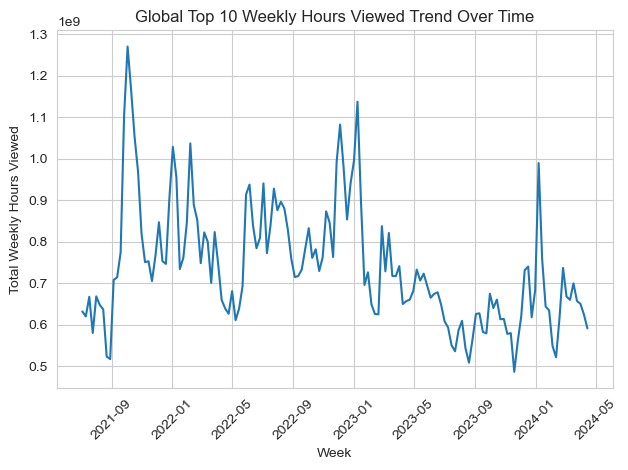

In [23]:
 
trend = nf_global.groupby('week')['weekly_hours_viewed'].sum().reset_index()

plt.figure()
plt.plot(trend['week'], trend['weekly_hours_viewed'])
plt.title("Global Top 10 Weekly Hours Viewed Trend Over Time")
plt.xlabel("Week")
plt.ylabel("Total Weekly Hours Viewed")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### 2.2(b) Create a barchart of Top 10 Most Popular Titles (First 91 Days Views)

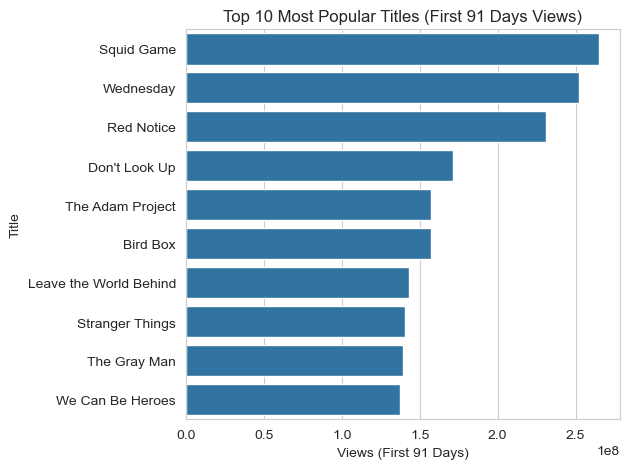

In [24]:

top_titles = popular.sort_values(by='views_first_91_days', ascending=False).head(10)

plt.figure()
sns.barplot(data=top_titles, x='views_first_91_days', y='show_title')
plt.title("Top 10 Most Popular Titles (First 91 Days Views)")
plt.xlabel("Views (First 91 Days)")
plt.ylabel("Title")
plt.tight_layout()
plt.show()

#### 2.2(c) Create a bar chart of Most Consistent Top 10 Titles

C:\Users\MAYMA\AppData\Local\Temp\ipykernel_45532\2067381213.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("Oranges")
C:\Users\MAYMA\AppData\Local\Temp\ipykernel_45532\2067381213.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


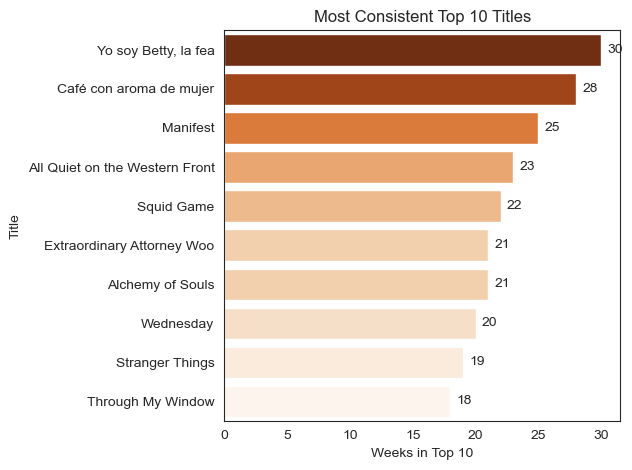

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.cm as cm

sns.set_style("white")  # remove background grid

consistency = nf_global.groupby('show_title')['cumulative_weeks_in_top_10'].max().reset_index()
top_consistent = consistency.sort_values(by='cumulative_weeks_in_top_10', ascending=False).head(10)

values = top_consistent['cumulative_weeks_in_top_10']
norm = (values - values.min()) / (values.max() - values.min())

cmap = cm.get_cmap("Oranges")
colors = [cmap(v) for v in norm]

plt.figure()
ax = sns.barplot(
    data=top_consistent,
    x='cumulative_weeks_in_top_10',
    y='show_title',
    palette=colors
)

# Add labels
for bar in ax.patches:
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2,
            f'{int(width)}', va='center')

ax.grid(False)  # ensure no gridlines

plt.title("Most Consistent Top 10 Titles")
plt.xlabel("Weeks in Top 10")
plt.ylabel("Title")
plt.tight_layout()
plt.show()

#### 2.2(d) Create a line charts of Category Performance Over Time

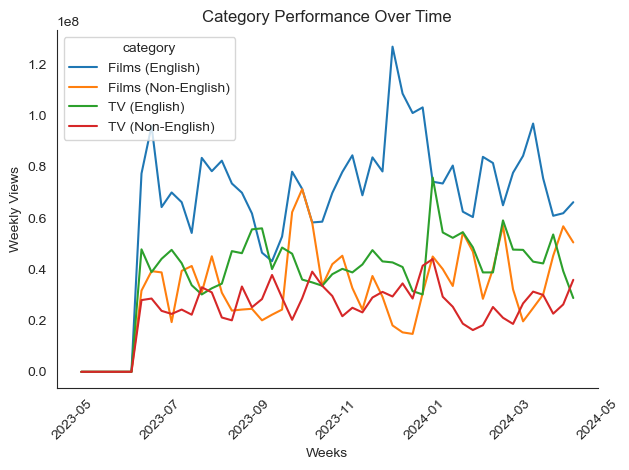

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure 'week' is datetime
nf_global['week'] = pd.to_datetime(nf_global['week'])

# Filter from May 2023 onward
filtered_df = nf_global[nf_global['week'] >= '2023-05-01']

# Recreate aggregated data
cat_trend = filtered_df.groupby(['week', 'category'])['weekly_views'].sum().reset_index()

# Remove grid style
sns.set_style("white")

plt.figure()
ax = sns.lineplot(data=cat_trend, x='week', y='weekly_views', hue='category')

# Remove any remaining gridlines
ax.grid(False)

plt.title("Category Performance Over Time")
plt.xlabel("Weeks")
plt.ylabel("Weekly Views")
plt.xticks(rotation=45)

sns.despine()

plt.tight_layout()
plt.show()

#### 2.2(e) Create a scatterplot of Runtime vs Views (First 91 Days)

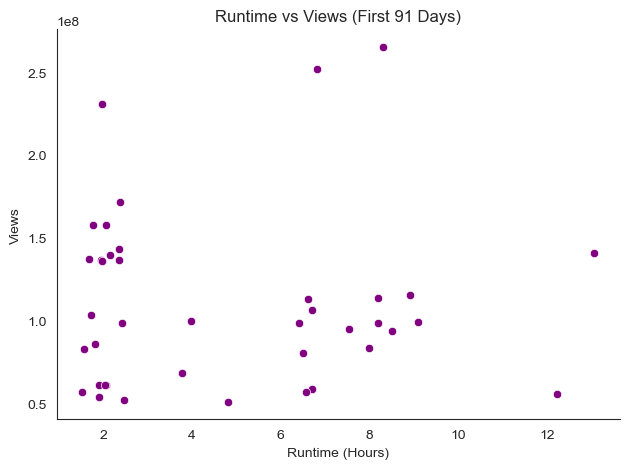

In [26]:
# Remove grid style
sns.set_style("white")

plt.figure()
ax = sns.scatterplot(
    data=popular,
    x='runtime',
    y='views_first_91_days',
    color='purple'  
)

# Ensure no gridlines
ax.grid(False)

plt.title("Runtime vs Views (First 91 Days)")
plt.xlabel("Runtime (Hours)")
plt.ylabel("Views")

# Optional: cleaner look
sns.despine()

plt.tight_layout()
plt.show()

#### 2.2(f) Create a map of Global Engagement by Country (Top 10 Appearances)

C:\Users\MAYMA\AppData\Local\Temp\ipykernel_45532\317703418.py:3: DeprecationWarning: The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.
  fig = px.choropleth(


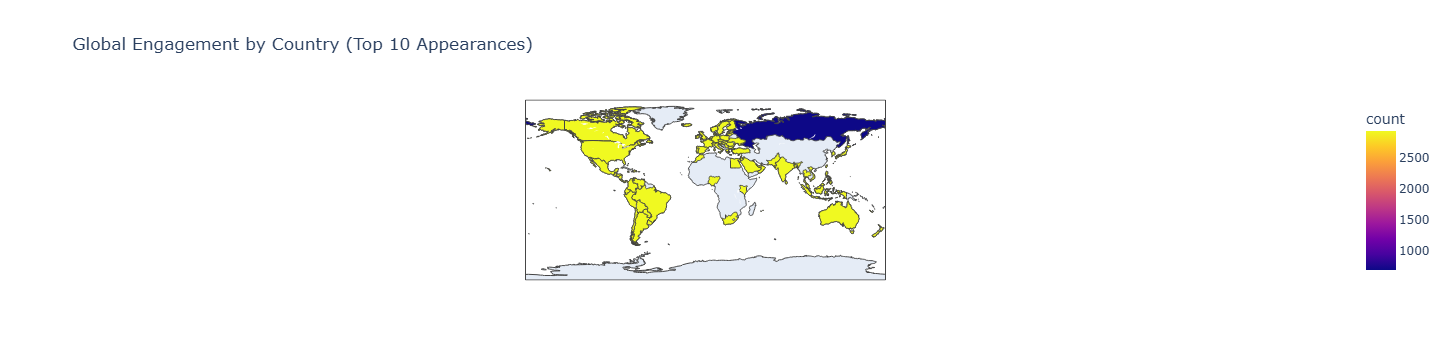

In [28]:
country_counts = nf_countries.groupby('country_name').size().reset_index(name='count')

fig = px.choropleth(
    country_counts,
    locations="country_name",
    locationmode="country names",
    color="count",
    title="Global Engagement by Country (Top 10 Appearances)"
)

fig.show()